# Семинар: линейная регрессия


In [428]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Сквозной пример

Три точки с лекции: (1; 2), (2; 3), (3; 5). На них проверим всё, что будем писать.

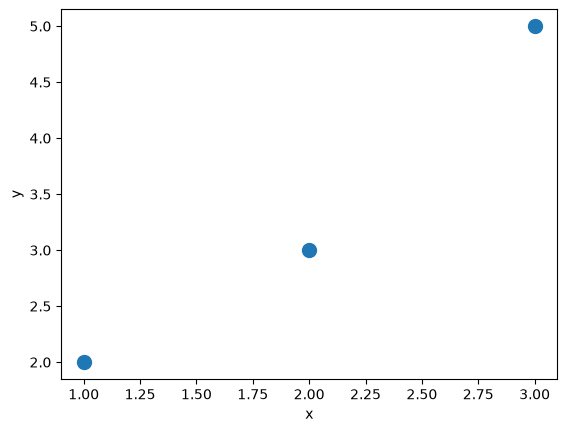

In [429]:
x = np.array([1, 2, 3])
y = np.array([2, 3, 5])

plt.scatter(x, y, s=100)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Модель - прямая: $a(x) = w_0 + w_1 x$. Чтобы сравнивать прямые, нужна ошибка.

## Ошибка MSE

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}\big(a(x_i) - y_i\big)^2$$

Возводим в квадрат, чтобы положительные и отрицательные ошибки не сокращались.

### Задание 1
Допишите функцию `mse(y_true, y_pred)`.

*Подсказка:* разность массивов, возведение в квадрат `** 2` и среднее `np.mean`.

In [430]:
import numpy as np
def mse(y_true, y_pred):
    n = y_true.shape[0]
    return np.sum((y_true - y_pred) ** 2) / n

In [431]:
import numpy as np
assert np.isclose(mse(np.array([1, 2]), np.array([1, 2])), 0)
assert np.isclose(mse(np.array([0, 0]), np.array([1, 3])), 5)
assert np.isclose(mse(y, 1 / 3 + 1.5 * x), 0.0556, atol=1e-4)
print("Верно!")

Верно!


Сравним несколько прямых по ошибке.

In [432]:
lines = {
    "y = 10/3 (среднее)": 10 / 3 + 0 * x,
    "y = 1.64*x": 1.64 * x,
    "y = 1/3 + 1.5*x": 1 / 3 + 1.5 * x,
}

for name, pred in lines.items():
    print(mse(y, pred))

1.5555555555555554
0.07146666666666666
0.05555555555555563


## 2. Решение формулой

Для одного признака лучшие веса находятся явно (вывод был на лекции):

$$w_1 = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2}, \qquad w_0 = \bar y - w_1 \bar x$$

### Задание 2
Допишите `fit_line(x, y)`: вернуть `w0` и `w1`.

*Подсказка:* среднее - `x.mean()`, сумма - `np.sum`.

In [433]:
def fit_line(x, y):
    w1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
    w0 = y.mean() - w1 * x.mean()
    return w0, w1

In [434]:
w0, w1 = fit_line(x, y)

assert np.isclose(w1, 1.5), f"Ожидали w1 = 1.5, получили {w1}"
assert np.isclose(w0, 1 / 3), f"Ожидали w0 = 1/3, получили {w0}"
assert np.allclose(fit_line(np.array([0, 1, 2]), np.array([1, 3, 5])), (1, 2)), "Для точек на прямой y = 1 + 2x"
print("Верно!")

Верно!


Сравним с готовой моделью из sklearn. Ей нужна **таблица** признаков: строки - объекты, столбцы - признаки.

In [435]:
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)

print(f"мы: w0 = {w0:.3f}, w1 = {w1:.3f}")
print(f"sklearn: w0 = {model.intercept_:.3f}, w1 = {model.coef_[0]:.3f}")

мы: w0 = 0.333, w1 = 1.500
sklearn: w0 = 0.333, w1 = 1.500


Интересное свойство: прямая МНК всегда проходит через точку средних $(\bar x; \bar y)$.

In [436]:
print("Среднее y:", y.mean())
print("Прогноз в среднем x:", w0 + w1 * x.mean())

Среднее y: 3.3333333333333335
Прогноз в среднем x: 3.3333333333333335


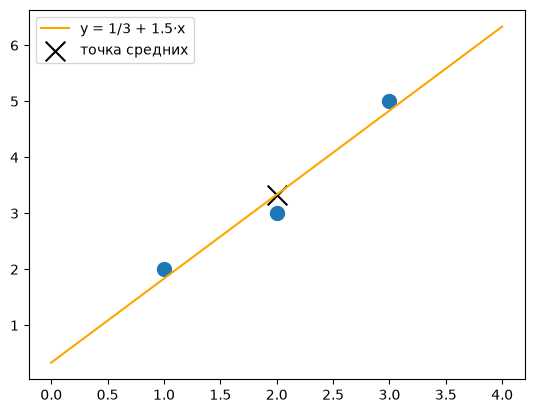

In [437]:
grid = np.linspace(0, 4, 50)

plt.scatter(x, y, s=100)
plt.plot(grid, w0 + w1 * grid, color="orange", label="y = 1/3 + 1.5·x")
plt.scatter([x.mean()], [y.mean()], marker="x", s=200, color="black", label="точка средних")
plt.legend()
plt.show()

### Матричная формула

Для любого числа признаков: $w = (X^T X)^{-1} X^T y$. В матрицу $X$ добавляем столбец единиц - он отвечает за $w_0$.

In [438]:
X = np.column_stack([np.ones(3), x])
print(X)

[[1. 1.]
 [1. 2.]
 [1. 3.]]


In [439]:
w = np.linalg.inv(X.T @ X) @ X.T @ y
print("w0, w1 =", w)

w0, w1 = [0.33333333 1.5       ]


## 3. Градиентный спуск

Формула требует обращать матрицу - при большом числе признаков это дорого. Градиентный спуск идёт к минимуму шагами:

$$\frac{\partial \text{MSE}}{\partial w_0} = \frac{2}{n}\sum_i e_i, \qquad \frac{\partial \text{MSE}}{\partial w_1} = \frac{2}{n}\sum_i e_i x_i, \qquad e_i = a(x_i) - y_i$$

Шаг: $w \leftarrow w - \eta \cdot \text{градиент}$.

### Задание 3
Допишите `gradient_step(w0, w1, x, y, lr)`: один шаг спуска, вернуть новые `w0` и `w1`.

План: 1) посчитать прогнозы; 2) посчитать остатки `e`; 3) посчитать два градиента; 4) сделать шаг.

In [440]:
def gradient_step(w0, w1, x, y, lr):
    pred = x * w1 + w0
    e = pred - y
    grad_w0 = 2 * np.sum(e, axis=0) / len(x)
    grad_w1 = 2 * np.sum(e * x, axis=0) / len(x)
    return w0 - lr * grad_w0, w1 - lr * grad_w1


In [441]:
# Проверка задания 3: тот же шаг, что мы считали на лекции
w0_new, w1_new = gradient_step(0.0, 0.0, x, y, lr=0.1)

assert np.isclose(w0_new, 0.6667, atol=1e-4), f"Ожидали w0 = 0.667, получили {w0_new}"
assert np.isclose(w1_new, 1.5333, atol=1e-4), f"Ожидали w1 = 1.533, получили {w1_new}"
print("Верно!")

Верно!


In [442]:
print(mse(y, 0 * x))
print("MSE до шага:", round(mse(y, 0 * x), 3))
print("MSE после шага:", round(mse(y, w0_new + w1_new * x), 3))

12.666666666666666
MSE до шага: 12.667
MSE после шага: 0.216


Один шаг уменьшил ошибку почти в 60 раз. Сделаем много шагов.

In [443]:
w0, w1 = 0.0, 0.0
history = []

for step in range(300):
    w0, w1 = gradient_step(w0, w1, x, y, lr=0.1)
    history.append(mse(y, w0 + w1 * x))


print(f"w0 = {w0:.3f}, w1 = {w1:.3f}, MSE = {history[-1]:.4f}")

w0 = 0.334, w1 = 1.500, MSE = 0.0556


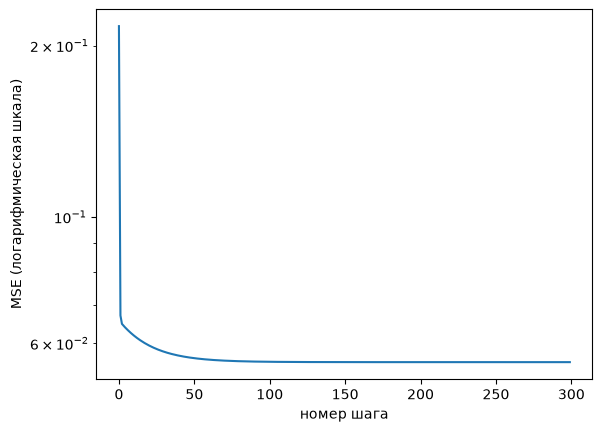

In [444]:
plt.plot(history)
plt.yscale("log")
plt.xlabel("номер шага")
plt.ylabel("MSE (логарифмическая шкала)")
plt.show()

Спуск пришёл к тому же решению, что и формула: $w_0 = 1/3$, $w_1 = 1{,}5$.

### Скорость обучения

Посмотрим, что будет при разных шагах `lr` (20 итераций).

In [445]:
for lr in [0.01, 0.1, 0.2]:
    w0, w1 = 0.0, 0.0
    for step in range(20):
        w0, w1 = gradient_step(w0, w1, x, y, lr)
    print(f"lr = {lr}:  MSE после 20 шагов = {mse(y, w0 + w1 * x):.3f}")

lr = 0.01:  MSE после 20 шагов = 0.180
lr = 0.1:  MSE после 20 шагов = 0.060
lr = 0.2:  MSE после 20 шагов = 34250.003


Маленький шаг - медленно, слишком большой - ошибка **растёт**, спуск расходится.

## 4. Реальная задача: цены квартир

Сгенерируем данные о квартирах: площадь, число комнат, расстояние до метро и цена.

In [446]:
rng = np.random.default_rng(7)
n = 200

area = np.clip(rng.normal(60, 20, n), 25, 150).round()
rooms = np.clip(np.round(area / 25 + rng.normal(0, 0.5, n)), 1, 5)
metro = rng.uniform(100, 3000, n).round(-1)
price = (1 + 0.15 * area + 0.4 * rooms - 0.0008 * metro + rng.normal(0, 1, n)).round(2)

In [447]:
df = pd.DataFrame({"площадь": area, "комнаты": rooms, "до_метро": metro, "цена": price})
df.head()

,площадь,комнаты,до_метро,цена
0,60.0,2.0,2430.0,9.93
1,66.0,3.0,920.0,11.76
2,55.0,2.0,2430.0,7.80
3,42.0,2.0,2140.0,6.75
4,51.0,3.0,1970.0,7.27


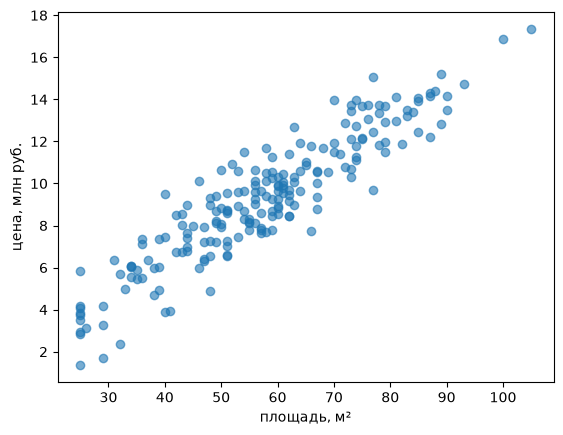

In [448]:
plt.scatter(df["площадь"], df["цена"], alpha=0.6)
plt.xlabel("площадь, м²")
plt.ylabel("цена, млн руб.")
plt.show()

Делим данные на обучающую и тестовую части. Качество всегда проверяем на тесте - на данных, которых модель не видела.

In [449]:
X = df[["площадь", "комнаты", "до_метро"]]
y = df["цена"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print("Обучение:", len(X_train), " Тест:", len(X_test))

Обучение: 150  Тест: 50


In [450]:
model = LinearRegression()
model.fit(X_train, y_train)

for name, coef in zip(X.columns, model.coef_):
    print(f"{name:<10} {coef:+.4f}")
print(f"w0         {model.intercept_:+.4f}")

площадь    +0.1480
комнаты    +0.3562
до_метро   -0.0008
w0         +1.1854


**Как читать веса:** +1 м² площади добавляет к цене около 0,15 млн руб. при прочих равных;
каждые 100 м до метро снижают цену примерно на 0,08 млн.

In [451]:
y_pred = model.predict(X_test)

print("Первые прогнозы:", y_pred[:5].round(2))
print("Настоящие цены: ", y_test.values[:5])

Первые прогнозы: [ 2.99  7.12 10.68  4.27  9.15]
Настоящие цены:  [ 2.83  8.   11.94  3.12 10.64]


## 5. Метрики качества

- **MSE** - средний квадрат ошибки (в «рублях в квадрате», трудно объяснить)
- **RMSE** = $\sqrt{\text{MSE}}$ - в тех же единицах, что и цена
- **MAE** - средний модуль ошибки, меньше реагирует на выбросы
- **R²** - насколько модель лучше, чем всегда отвечать средним:

$$R^2 = 1 - \frac{\sum_i (a(x_i) - y_i)^2}{\sum_i (\bar y - y_i)^2}$$

### Задание 4
Допишите `r2(y_true, y_pred)`.

*Подсказка:* числитель - сумма квадратов ошибок модели, знаменатель - сумма квадратов отклонений `y_true` от своего среднего.

In [452]:
def r2(y_true, y_pred):
    e = y_pred - y_true

    R2 = 1 - (np.sum(e ** 2) / np.sum((y_true.mean() - y_true) ** 2))
    return R2

In [453]:
# Проверка задания 4
y3 = np.array([2, 3, 5])

assert np.isclose(r2(y3, 1 / 3 + 1.5 * np.array([1, 2, 3])), 0.9643, atol=1e-4), "Сквозной пример: R^2 = 0.964"
assert np.isclose(r2(y3, np.full(3, y3.mean())), 0), "Модель «всегда среднее»: R^2 = 0"
assert np.isclose(r2(y_test.values, y_pred), r2_score(y_test, y_pred)), "Должно совпасть с sklearn"
print("Верно!")

Верно!


In [454]:
print("MSE: ", round(mse(y_test.values, y_pred), 3))
print("RMSE:", round(np.sqrt(mse(y_test.values, y_pred)), 3), "млн руб.")
print("MAE: ", round(mean_absolute_error(y_test, y_pred), 3), "млн руб.")
print("R²:  ", round(r2(y_test.values, y_pred), 3))

MSE:  0.798
RMSE: 0.893 млн руб.
MAE:  0.742 млн руб.
R²:   0.92


R² может быть **отрицательным**, если модель хуже, чем просто среднее. Например, если по ошибке прибавить ко всем прогнозам 5 млн:

In [455]:
print("R^2 испорченной модели:", round(r2(y_test.values, y_pred + 5), 3))

R^2 испорченной модели: -1.579


## 6. Нормализация признаков

Признаки в очень разных масштабах: площадь - десятки, комнаты - единицы, до метро - тысячи.

In [456]:
X_train.describe().loc[["mean", "std", "min", "max"]].round(1)

,площадь,комнаты,до_метро
mean,58.1,2.3,1615.3
std,16.8,0.9,748.5
min,25.0,1.0,140.0
max,105.0,4.0,3000.0


### Веса нельзя сравнивать напрямую

Вес «до метро» самый маленький по модулю, но это не значит, что признак неважен - просто он измеряется в метрах.
После стандартизации $x' = (x - \mu) / \sigma$ вес показывает изменение цены при росте признака на одно стандартное отклонение.

In [457]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # μ и σ считаем только по обучению
X_test_s = scaler.transform(X_test)           # тест преобразуем теми же μ и σ

In [458]:
model_s = LinearRegression().fit(X_train_s, y_train)

for name, raw, scaled in zip(X.columns, model.coef_, model_s.coef_):
    print(f"{name:<10} исходный вес {raw:+.4f}    после нормализации {scaled:+.3f}")

площадь    исходный вес +0.1480    после нормализации +2.478
комнаты    исходный вес +0.3562    после нормализации +0.319
до_метро   исходный вес -0.0008    после нормализации -0.583


In [459]:
print("R^2 на тесте без нормализации:", round(model.score(X_test, y_test), 3))
print("R^2 на тесте с нормализацией: ", round(model_s.score(X_test_s, y_test), 3))

R^2 на тесте без нормализации: 0.92
R^2 на тесте с нормализацией:  0.92


Прогнозы формулы не изменились - изменились только веса. А вот **градиентному спуску** нормализация очень нужна.
Функция ниже - тот же спуск, но сразу для всех признаков (в матричном виде).

In [460]:
def run_gd(X, y, lr, steps):
    X1 = np.column_stack([np.ones(len(X)), X])        # добавили столбец единиц
    w = np.zeros(X1.shape[1])
    for _ in range(steps):
        w = w - lr * 2 / len(y) * X1.T @ (X1 @ w - y)
    return mse(y, X1 @ w)

In [461]:
best = mse(y_train.values, model.predict(X_train))

print("Лучшая возможная MSE:            ", round(best, 3))
print("Без нормализации, 1000 шагов:    ", round(run_gd(X_train.values, y_train.values, lr=1e-7, steps=1000), 3))
print("С нормализацией, всего 100 шагов:", round(run_gd(X_train_s, y_train.values, lr=0.1, steps=100), 3))

Лучшая возможная MSE:             1.053
Без нормализации, 1000 шагов:     20.756
С нормализацией, всего 100 шагов: 1.053


Без нормализации приходится брать крошечный шаг (иначе спуск разойдётся из-за признака «до метро»),
и за 1000 шагов модель ещё очень далека от минимума. После нормализации хватает 100 шагов.

## 7. Выбросы

Из-за квадратов одна большая ошибка сильно влияет и на обучение, и на метрики.
Вернёмся к трём точкам и добавим одну «странную» точку.

In [462]:
x_out = np.array([1, 2, 3, 4])
y_out = np.array([2, 3, 5, 15])

w0_a, w1_a = fit_line(x, np.array([2, 3, 5]))
w0_b, w1_b = fit_line(x_out, y_out)

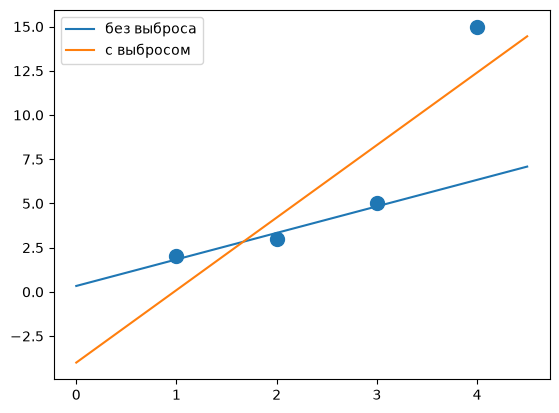

In [463]:
grid = np.linspace(0, 4.5, 50)

plt.scatter(x_out, y_out, s=100)
plt.plot(grid, w0_a + w1_a * grid, label="без выброса")
plt.plot(grid, w0_b + w1_b * grid, label="с выбросом")
plt.legend()
plt.show()

In [464]:
errors = np.array([1, 1, 1, 1, 20])

print("MAE: ", errors.mean())
print("RMSE:", round(np.sqrt(np.mean(errors ** 2)), 2))

MAE:  4.8
RMSE: 8.99
